# Lifespan Predictor — Telling Two Failure Modes Apart

Engines can fail for more than one reason, and a fleet rarely comes labelled
with which engine is wearing which way. This notebook trains the
interpretable Cox model on NASA's C-MAPSS **FD003** and uses its per-engine
explanations to find the two failure modes in the data, then checks them
against the raw sensor readings.

FD003's engines fail by one of two faults: a degrading **high-pressure
compressor** (HPC) or a degrading **fan**, according to NASA's `readme.txt`
for the dataset, which `download_nasa_dataset` saves in `data/nasa`. The data
says nothing about which engine has which.

The notebook runs end to end with no edits: one training job, one batch
transform, and it deletes what it made. It runs on either Lifespan Predictor
product, including the **free tier**: FD003 has 100 training
engines, within the free tier's cap. See [Which product?](https://github.com/kooditurva/lifespan-predictor-sdk#which-product).

`sagemaker_coxph_demo.ipynb` introduces the model and both analyses on FD001,
which has one failure mode. Start there if they are new to you.

## 1. Install the SDK

The client SDK is installed from its GitHub release tag. It is not
published to PyPI.

In [ ]:
# Other releases: https://github.com/kooditurva/lifespan-predictor-sdk/releases
!pip install -q "lifespan-predictor @ git+https://github.com/kooditurva/lifespan-predictor-sdk@v1.1.0"

## 2. Point at the algorithm you subscribed to

The ARN below is the free tier's, in `eu-west-1`. If you subscribed to
the other product or work in another Region, use the ARN listed under
[Which product?](https://github.com/kooditurva/lifespan-predictor-sdk#which-product), or find it in the AWS Marketplace
console: **Manage subscriptions**, select the product, choose
**Continue to configuration**, and pick your Region.

The execution role is the IAM role SageMaker assumes to run your
training jobs. The SDK reads it from `SAGEMAKER_ROLE_ARN`. Outside
SageMaker Studio, set that variable before starting Jupyter; in Studio,
the cell below sets it from `get_execution_role()`.

In [2]:
import os

import matplotlib.pyplot as plt

from lifespan_predictor_sdk import (
    CategoricalRange,
    ContinuousRange,
    SurvivalModel,
    download_nasa_dataset,
    get_nasa_test_dataframe,
    get_nasa_train_dataframe,
)

ALGORITHM_ARN = 'arn:aws:sagemaker:eu-west-1:985815980388:algorithm/free-tier-lifespan-predictor-m-25f11987ba043299a755d4e16601168e'

if 'SAGEMAKER_ROLE_ARN' not in os.environ:
    from sagemaker import get_execution_role

    os.environ['SAGEMAKER_ROLE_ARN'] = get_execution_role()

### Check your setup

What the SDK will use. Set `SAGEMAKER_BUCKET` to keep the data and models
in a bucket of your own; otherwise SageMaker's default bucket for your
account and Region is used, and created if needed.

In [3]:
from importlib.metadata import version

import boto3

region = boto3.Session().region_name
arn_region = ALGORITHM_ARN.split(':')[3]

print('SDK version:        ', version('lifespan-predictor'))
print('Region:             ', region)
print('AWS_PROFILE:        ', os.environ.get('AWS_PROFILE', '(not set)'))
print('SAGEMAKER_ROLE_ARN: ', os.environ['SAGEMAKER_ROLE_ARN'])
print('SAGEMAKER_BUCKET:   ', os.environ.get(
    'SAGEMAKER_BUCKET', "(not set: SageMaker's default bucket)"))
print('Algorithm ARN:      ', ALGORITHM_ARN)

if region != arn_region:
    print(f'Warning: the session is in {region}, but the algorithm is in '
          f'{arn_region}. Use the ARN for your Region.')

SDK version:         1.1.0
Region:              eu-west-1
AWS_PROFILE:         (not set)
SAGEMAKER_ROLE_ARN:  arn:aws:iam::111122223333:role/lifespan-predictor-buyer-sagemaker
SAGEMAKER_BUCKET:    kooditurva-lifespan-predictor-buyer-ci
Algorithm ARN:       arn:aws:sagemaker:eu-west-1:985815980388:algorithm/free-tier-lifespan-predictor-m-25f11987ba043299a755d4e16601168e


In [4]:
SAGEMAKER = {
    'algorithm_arn': ALGORITHM_ARN,
    'instance_type': 'ml.m5.large',
}

## 3. Load FD003

The same shape as FD001: one row per engine and flight cycle, the engine's
`duration` and `event`, and its sensor readings `f1` to `f21`. The test
engines' histories stop before failure; `test_labels_df` holds their true
remaining life.

In [5]:
data_dir = 'data/nasa'
download_nasa_dataset(data_dir, datasets=[3])

train_df = get_nasa_train_dataframe(data_dir, datasets=[3])
test_df, test_labels_df = get_nasa_test_dataframe(data_dir, datasets=[3])

print(f"Training: {train_df['unit'].nunique()} engines, {len(train_df)} rows")
print(f"Test:     {test_df['unit'].nunique()} engines, {len(test_df)} rows")

Training: 100 engines, 24720 rows
Test:     100 engines, 16596 rows


## 4. Tune and train

The same tuning as on FD001: the penalty's strength and L1 share, and whether
the model also sees each sensor's rolling means. All of it runs inside one
training job, which also scores the model on the test engines.

val_split=0.2: 80 train units, 20 val units (19924 train rows, 4796 val rows)


🚀 Starting SageMaker training...


📦 S3 bucket: kooditurva-lifespan-predictor-buyer-ci
🔑 IAM Role: arn:aws:iam::111122223333:role/lifespan-predictor-buyer-sagemaker
🔖 Algorithm ARN: arn:aws:sagemaker:eu-west-1:985815980388:algorithm/free-tier-lifespan-predictor-m-25f11987ba043299a755d4e16601168e
📤 Uploading raw CSV data to S3...
  ✓ Saved train.csv (19924 rows)


  ✓ Saved val.csv (4796 rows)
  ✓ Saved test.csv (16596 rows)
  ✓ Saved test_labels.csv (100 rows)


✓ Raw CSV uploaded to: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/training-1793216123
⚙️  Configuring training job...
📋 Training config keys: ['model_type', 'max_rul', 'calibration', 'n_trials', 'coxph_penalizer', 'coxph_l1_ratio', 'rolling_means', 'sdk_version']
📋 Config size: 368 chars


...

Training seconds: 1032
Billable seconds: 1032


✓ Training completed!

Training Job Summary:
  Name: survival-model-2026-10-28-19-35-25-712
  Status: Completed
  Training Time: 1032 seconds
  Billable Time: 1032 seconds
  Instance Type: ml.m5.large
  Model artifacts: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output/survival-model-2026-10-28-19-35-25-712/output/model.tar.gz
  Debug output: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output
  Hyperparameters: 1 configured

  Final Metrics:
    test:c_index: 0.8816
    test:rmse: 14.7571


✓ Training job: survival-model-2026-10-28-19-35-25-712
✓ Model artifact: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/output/survival-model-2026-10-28-19-35-25-712/output/model.tar.gz
📥 Downloading training metrics...


✓ Test C-index: 0.8816
✓ Test RMSE: 14.7571
✓ Calibration bias: -0.0426 (well-calibrated)
✓ IBS: 0.0643 (excellent)


✓ tuning_trials loaded: 12 trials
✓ Training complete!
=== Evaluation Metrics ===
  Scored on 100 units. 15 have a true remaining life beyond max_rul=125, the
  horizon the model predicts: RMSE counts them as 125, and the C-indices and
  IBS treat them as censored at 125. Calibration bias uses the 85 that
  failed within max_rul=125.
  C-index (IPCW):       0.8816  (higher is better, 0.5 = random; corrected for censoring)
  C-index (Harrell):    0.8816  (uncorrected; the tuning metric)
  C-index (Antolini):   0.8816  (higher is better, time-dependent)
  RMSE:                 14.7571  (lower is better)
  IBS:                  0.0643  (lower is better, <0.1 = excellent)  (excellent)
  Calibration bias:     -0.0426  (closer to 0 is better)  (well-calibrated)
Prediction arrays not available (e.g. SageMaker backend).


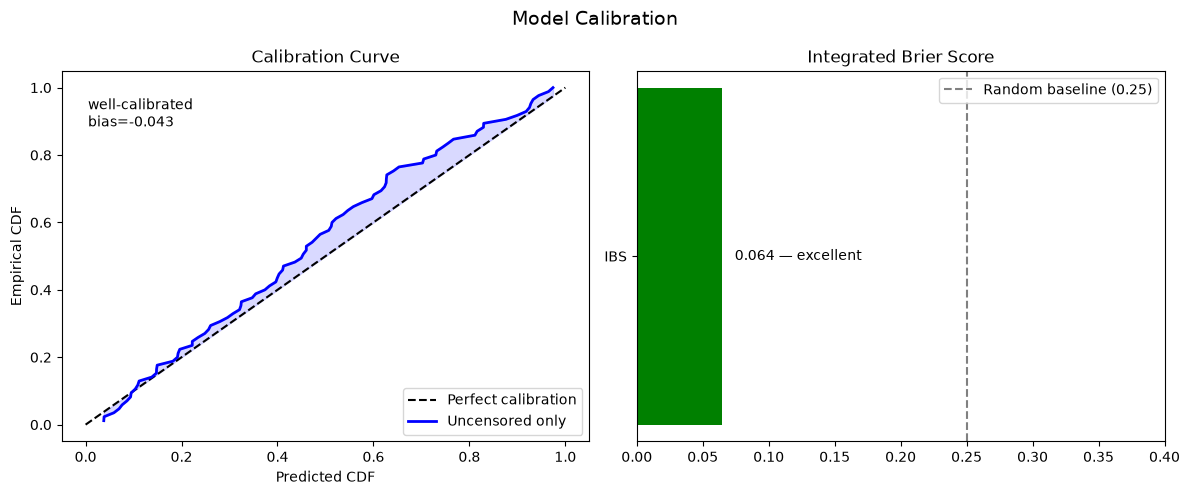

In [6]:
model = SurvivalModel({
    **SAGEMAKER,
    'model_type': 'coxph',
    'max_rul': 125,
    'calibration': 'isotonic',
    'n_trials': 12,
    'coxph_penalizer': ContinuousRange(1e-3, 10.0, log=True),
    'coxph_l1_ratio': ContinuousRange(0.0, 1.0),
    'rolling_means': CategoricalRange([[], [5, 10, 20, 30]]),
})

model.fit(train_df, val_split=0.2, test_df=test_df, test_labels_df=test_labels_df)
model.get_evaluation_result().report()

## 5. Predict, and explain each engine

`get_local_analysis()` splits each test engine's predicted risk exactly into
what each sensor contributes: positive raises it, negative lowers it, against
the average training row.

In [7]:
model_name = model.deploy()
print('Created SageMaker model:', model_name)

🚀 Creating SageMaker Model for batch transform...
🔑 IAM Role: arn:aws:iam::111122223333:role/lifespan-predictor-buyer-sagemaker


📦 Model name: coxph-2026-10-28-19-53-37-276
✅ Model created successfully!
   Ready for batch transform inference

Next steps:
  mean_times = model.predict_mean(test_df)

Created SageMaker model: coxph-2026-10-28-19-53-37-276


🔮 Running batch transform for mean survival predictions...
   Input: 16596 samples
📤 Uploading input data to S3...


✓ Input uploaded: s3://kooditurva-lifespan-predictor-buyer-ci/lifespan-predictor/batch-input-1793217269/input.csv


🏃 Starting batch transform job...
   Instance: ml.m5.large (count: 1)


.

.

...

[2026-10-28 19:59:16 +0000] [1] [INFO] Starting gunicorn 26.2.0
[2026-10-28 19:59:16 +0000] [1] [INFO] Listening at: http://0.0.0.0:8080 (1)
[2026-10-28 19:59:16 +0000] [1] [INFO] Using worker: sync
[2026-10-28 19:59:16 +0000] [6] [INFO] Booting worker with pid: 6
[2026-10-28 19:59:16 +0000] [1] [INFO] Control socket listening at /root/.gunicorn/gunicorn.ctl
Starting model loading in background thread...
Loading model from /opt/ml/model...
Loading model from /opt/ml/model
✓ Model loaded successfully
  Model type: coxph
  Features: 120
✓ Model loaded successfully


2026-10-28T19:59:26.934:[sagemaker logs]: MaxConcurrentTransforms=1, MaxPayloadInMB=6, BatchStrategy=MULTI_RECORD


✅ Batch transform complete!
📥 Downloading results from S3...


   Found 1 output file(s)


✓ Results downloaded: 100 predictions
100 survival curves, one per test engine


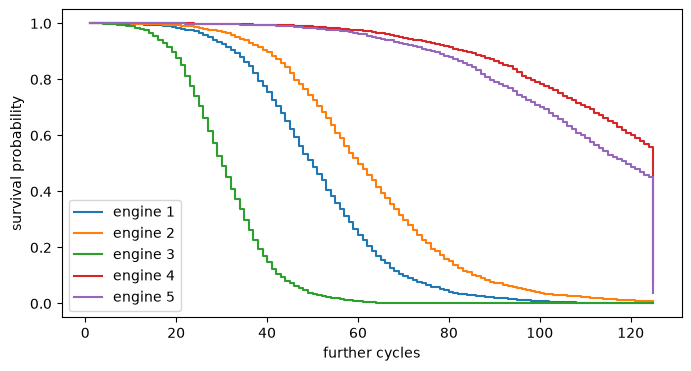

In [8]:
curves = model.predict(test_df)
units = sorted(test_df['unit'].unique())
print(f'{curves.shape[1]} survival curves, one per test engine')

ax = curves.iloc[:, :5].plot(drawstyle='steps-post', figsize=(8, 4))
ax.set_xlabel('further cycles')
ax.set_ylabel('survival probability')
ax.legend([f'engine {u}' for u in units[:5]])
plt.show()

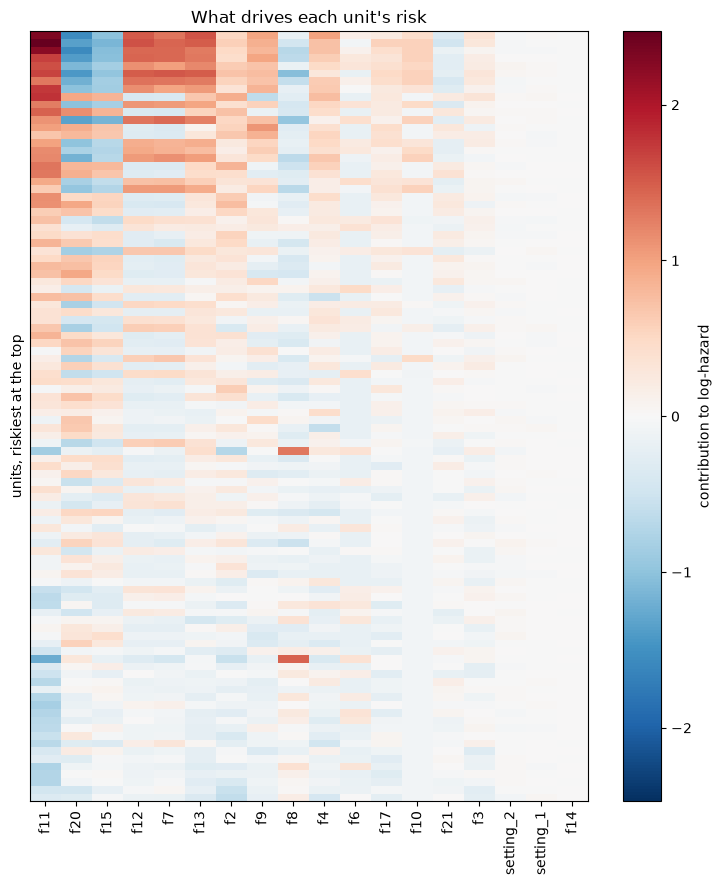

In [9]:
import numpy as np
import pandas as pd
from IPython.display import display

local = model.get_local_analysis()
risk_order = local.log_hazard_ratio.sort_values(ascending=False).index
fig, ax = local.plot_contributions()

## 6. Which sensors move together

`feature_groups()` puts sensors whose contributions correlate across the
engines into one group. On FD001, with one fault, most sensors join one large
group: they are readings of the same wear. A second fault that moves some of
those sensors the other way pulls them out of it, so on FD003 look for the
large group to split.

,sensors
group,
f17,1
f2 + f11,2
f3,1
f4,1
f6,1
f7 + f10 + f12 + f13 + f15 + f20 + f21,7
f8,1
f9 + f14,2
setting_1,1


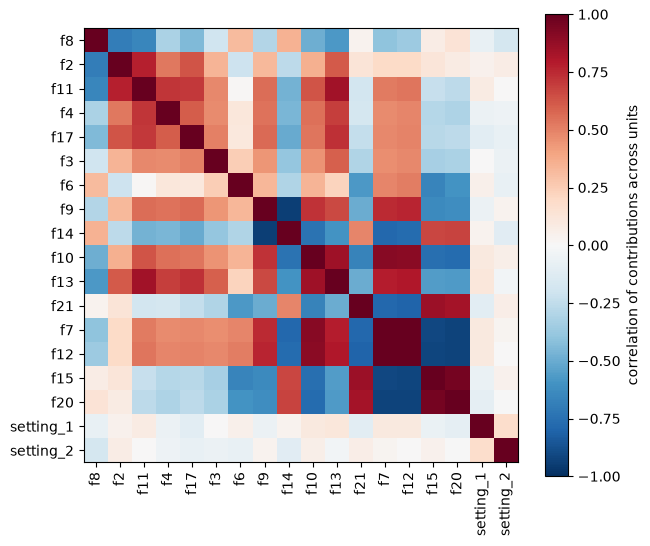

In [10]:
groups = local.feature_groups(min_correlation=0.7)
display(groups.groupby(groups).size().rename('sensors').to_frame())
fig, ax = local.plot_feature_correlation()

### The top driver alone misses it

Counting each engine's leading group answers "what drives risk" one engine
at a time. Both faults share most of the sensors that carry risk, so the same
group leads most engines either way, and the count shows little sign of two
modes.

In [11]:
local.top_drivers(groups).value_counts().rename(
    'engines where it is the top driver').to_frame()

,engines where it is the top driver
top_driver,
f2 + f11,55
f7 + f10 + f12 + f13 + f15 + f20 + f21,31
f9 + f14,5
f4,4
f6,3
f8,1
f17,1


## 7. Engines explained alike

What tells the faults apart is the *pattern* of an engine's explanation,
not its largest part. `similarity()` compares every pair of engines' patterns,
from `1`, the same, to `-1`, the mirror image. With engines in risk order, two
blocks along the diagonal at the top are two groups of worn engines explained
differently. Healthy engines, at the bottom, have small contributions whose
pattern says little.

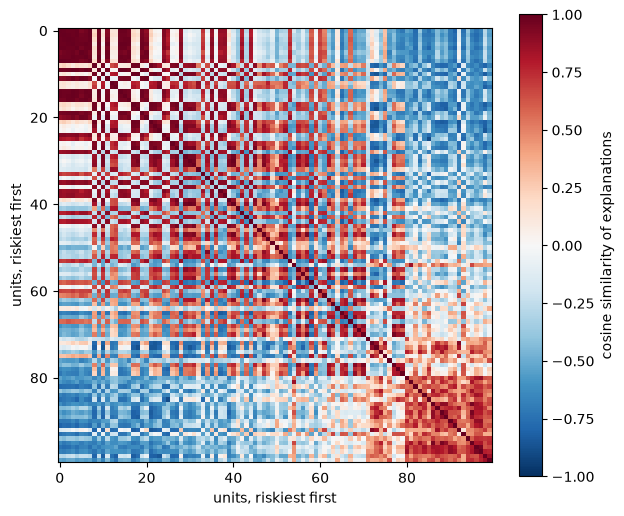

In [12]:
fig, ax = local.plot_similarity()

### Cluster the riskiest engines

`cluster_units()` groups engines by how alike their explanations are.
Restricting it to the 40 riskiest leaves out the healthy engines, whose
explanations are close to zero. The table after it is each cluster's mean
contribution per sensor: where the two clusters differ in sign, the model
sees two different faults.

In [13]:
engines = risk_order[:40]
clusters = local.cluster_units(n_clusters=2, units=engines)
display(clusters.value_counts().rename('engines').to_frame())
local.contributions.loc[engines].groupby(clusters).mean().T.round(2)

,engines
cluster,
2,22
1,18


cluster,1,2
setting_1,-0.00,0.00
setting_2,0.00,0.01
setting_3,0.00,0.00
f1,0.00,0.00
f2,0.51,0.30
f3,0.04,0.12
f4,0.25,0.42
f5,0.00,0.00
f6,-0.19,0.18
f7,-0.30,0.93


## 8. Check against the raw data

The clusters come from the model. To check them without it, measure how each
test engine's sensors moved over its history: the mean of its last 10
cycles against its first 30, in units of the sensor's spread in the
training data. In FD003, `f7`, `f12`, `f20` and `f21` rise in one fault and
fall in the other, while `f15` moves the opposite way to them. The score below
is positive for one fault and negative for the other. Engines that have
barely worn score near zero and are left unclear. If the model's clusters
line up with the score's two sides, they are the two failure modes.

In [14]:
SPLIT = ['f7', 'f12', 'f20', 'f21']
SENSORS = SPLIT + ['f15']


def drift(df, spread):
    """Per engine: its last 10 cycles against its first 30, in spreads."""
    df = df.sort_values(['unit', 'cycles'])
    early = df.groupby('unit').head(30).groupby('unit')[SENSORS].mean()
    late = df.groupby('unit').tail(10).groupby('unit')[SENSORS].mean()
    return (late - early) / spread


moved = drift(test_df, train_df[SENSORS].std())
score = moved[SPLIT].mean(axis=1) - moved['f15']
side = pd.cut(score, [-np.inf, -0.5, 0.5, np.inf],
              labels=['negative', 'unclear', 'positive'])
pd.crosstab(clusters, side.loc[engines].rename('drift score'))

drift score,negative,unclear,positive
cluster,,,
1,17,1,0
2,0,0,22


## 9. Clean up

Delete the SageMaker model this notebook created. Training and transform
jobs are billed for the time they ran and stop on their own.

In [15]:
model.delete()
print('Deleted', model_name)

Deleted coxph-2026-10-28-19-53-37-276


## Where to go next

- **Your own fleet**: the same calls work on any data in this shape. Raise
  `n_clusters` if you suspect more than two mechanisms, and compare the
  clusters' mean contributions to name them.
- **Fewer engines**: subsample the training engines to see how many failures
  the split needs.

Full documentation is in the SDK repository:
https://github.com/kooditurva/lifespan-predictor-sdk